# Bentham test images — quick demo

View two random original line images and their unchanged ground-truth transcriptions using the same local loader as Experiment A Part 3. This is visual inspection only; no model inference, preprocessing selection, or evaluation runs here.

Run all cells. Change `SEED` for another reproducible pair, or set it to `None` for fresh random examples each time. Increase `N_EXAMPLES` to see more. Transparent pixels display on white without changing the source images. Dependencies: the existing project environment (`datasets`, Pillow, IPython) and downloaded Bentham files under `data/bentham`.

In [1]:
from pathlib import Path
import base64
from io import BytesIO
import random
import sys
from html import escape

from IPython.display import HTML, display

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'src/load_dataset/bentham.py').is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.load_dataset.bentham import load_bentham_dataset, REVISION

SEED = None
N_EXAMPLES = 5

In [2]:
test_dataset = load_bentham_dataset(split='test')
print(f'Bentham test lines: {len(test_dataset):,}')
print(f'Source revision: {REVISION}')

Bentham test lines: 860
Source revision: bfd99574602e2abbe7896255b1fd5e114f68571a


Seed: None; test indices: [288, 850, 105, 650, 768]



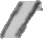


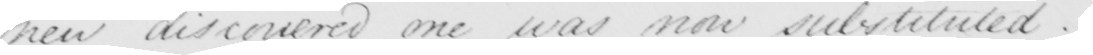


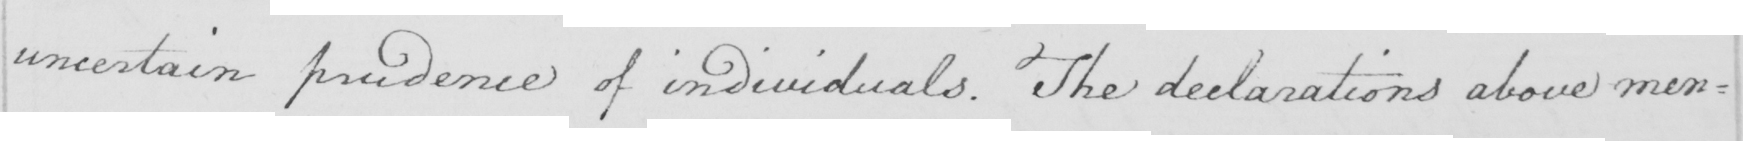


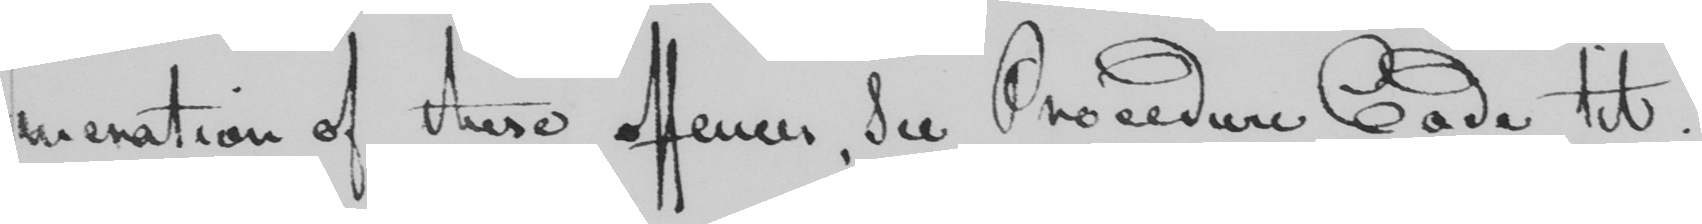


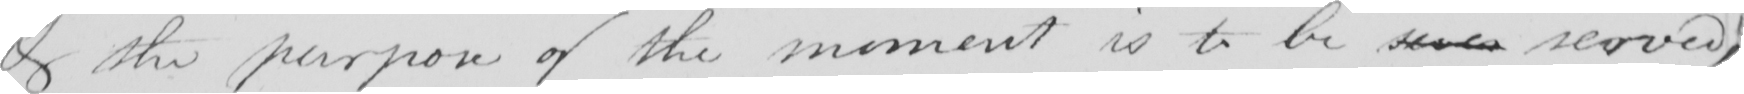

In [3]:
if not 1 <= N_EXAMPLES <= len(test_dataset):
    raise ValueError('N_EXAMPLES must be between 1 and the test split size.')

sample_indices = random.Random(SEED).sample(range(len(test_dataset)), N_EXAMPLES)
print(f'Seed: {SEED}; test indices: {sample_indices}')

for index in sample_indices:
    row = test_dataset[index]
    image = row['image']
    display(HTML(
        f'<h3>Test index {index} — {escape(row["id"])}</h3>'
        f'<p>{image.width} × {image.height} pixels; original mode: {image.mode}</p>'
    ))
    # Embed original pixels; the browser scales only their display.
    buffer = BytesIO()
    image.save(buffer, format='PNG')
    encoded = base64.b64encode(buffer.getvalue()).decode('ascii')
    display(HTML(
        f'<img src="data:image/png;base64,{encoded}" '
        'style="max-width:100%;height:auto;background:white" alt="Bentham handwritten line">'
        f'<pre style="white-space:pre-wrap">Ground truth: {escape(row["text"])}</pre>'
    ))